# Ecoverse 813 — 01 · Hyperspectral view of the Bahrain AOI (NASA EMIT)
**Question:** which soil and plant signals that matter for plant survival in Bahrain *need* a hyperspectral sensor (EMIT today,
Satellite 813 tomorrow), and which can the free Sentinel-2 satellite already approximate?

**Data:** NASA EMIT L2A surface reflectance (285 bands, 381–2493 nm, 60 m) over **the same northern-central Bahrain AOI** as the main
analysis, acquired **17 June 2023** with no cloud. `scripts/fetch_data.py` (or `notebooks/00`) downloads the scene, removes the
water-vapour and noisy edge bands, cuts a window around the AOI and saves a compact subset to `data/sample_input/emit_bahrain/`.

**Method:** continuum-removed absorption depths (gypsum 1750 nm, clay 2200 nm, carbonate 2340 nm, liquid water 1200 nm) and red-edge
position; Sentinel-2 bands simulated from the EMIT spectrum with Gaussian spectral responses; spatially-blocked 5-fold
cross-validation (32 × 32 pixel blocks, ≈ 1.9 km) so neighbouring pixels never sit on both sides of a split.

In [1]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=RuntimeWarning)   # all-NaN medians at scene edges

from ecoverse import config, io, fingerprint, plants, recommend, uncertainty, hyperspectral, emit, viz, report
np.random.seed(config.RANDOM_SEED)
pd.set_option("display.width", 160, "display.max_columns", 20, "display.precision", 3)
print("Repository root:", ROOT.name)
print("Results folder :", config.RESULTS_DIR.relative_to(ROOT) if config.RESULTS_DIR.is_relative_to(ROOT) else config.RESULTS_DIR)

Repository root: ecoverse-final
Results folder : results


In [2]:
E, emeta = emit.load_emit()
layers, profile = io.read_stack(config.STACK_TIF)
edf = emit.pixel_table(E, emeta)
pd.Series({k: emeta[k] for k in ["granule", "datetime", "sensor", "n_bands_total", "n_bands_used", "pixel_size_m", "aoi_valid_pct"]}, name="value").to_frame()

,value
granule,EMIT_L2A_RFL_002_20230617T111139
datetime,2023-06-17T11:11:39Z
sensor,NASA EMIT (ISS)
n_bands_total,285
n_bands_used,237
pixel_size_m,60
aoi_valid_pct,100.0


## 1 · Hyperspectral feature maps of the Bahrain AOI (resampled to the 20 m grid)

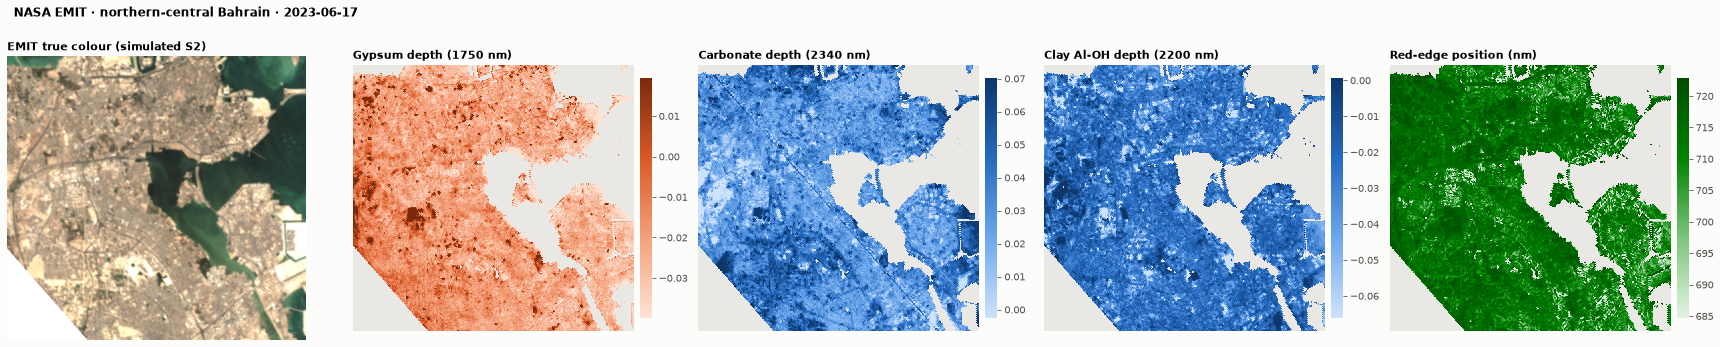

In [3]:
eg = emit.to_aoi_grid(E, profile)
land = np.isfinite(eg["B04"]) & (hyperspectral.nd(eg["B03"], eg["B11"]) < 0)
fig, ax = plt.subplots(1, 5, figsize=(24, 5.2))
rgb = np.dstack([eg["B04"], eg["B03"], eg["B02"]])
ax[0].imshow(np.clip(np.nan_to_num(rgb, nan=1) * 3.2, 0, 1)); ax[0].set_title("EMIT true colour (simulated S2)", loc="left"); ax[0].axis("off")
specs = [("GYPSUM_1750", "Gypsum depth (1750 nm)", viz.SEQ_ORANGE), ("CARBONATE_2340", "Carbonate depth (2340 nm)", viz.SEQ_BLUE),
         ("CLAY_2200", "Clay Al-OH depth (2200 nm)", viz.SEQ_BLUE), ("REP", "Red-edge position (nm)", viz.SEQ_GREEN)]
for a, (k, t, cm) in zip(ax[1:], specs):
    arr = np.where(land, eg[k], np.nan); v = arr[np.isfinite(arr)]
    viz._map(a, arr, t, cm, *np.percentile(v, [2, 98]))
fig.suptitle(f"NASA EMIT · northern-central Bahrain · {emeta['datetime'][:10]}", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); viz.save(fig, "10_emit_features_bahrain.png"); plt.show()

## 2 · Bahrain soil-surface types and their spectra
Bare-ground pixels are clustered on four narrow-band absorption depths that only a hyperspectral sensor resolves; mean spectra per class are reconstructed from the PCA of the full EMIT spectrum.

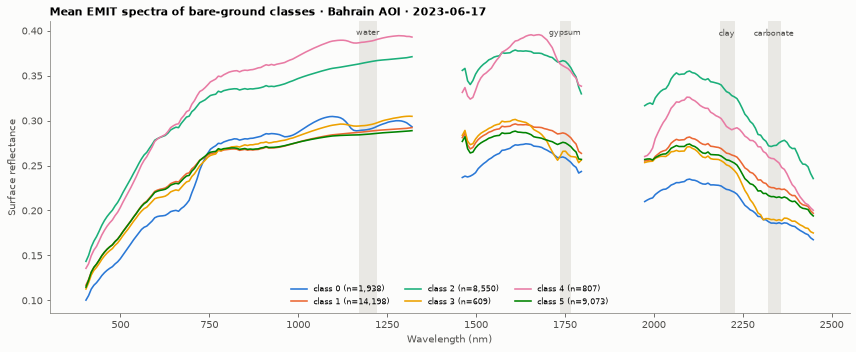

In [4]:
rec = hyperspectral.soil_class_recovery(edf, k=6)
labels = pd.Series(rec["labels"], index=rec["index"])
wl, spectra = emit.mean_spectra(E, labels, edf)
fig, ax = plt.subplots(figsize=(12, 5))
gaps = np.r_[False, np.diff(wl) > 20]
for k, spec in spectra.items():
    y = spec.astype(float); y[gaps] = np.nan
    ax.plot(wl, y, color=viz.CAT[int(k) % 8], lw=1.6, label=f"class {k} (n={int((labels == k).sum()):,})")
for lo_, hi_, name in [(1735, 1765, "gypsum"), (2185, 2225, "clay"), (2320, 2355, "carbonate"), (1170, 1220, "water")]:
    ax.axvspan(lo_, hi_, color="#e9e8e4", zorder=0); ax.text((lo_+hi_)/2, ax.get_ylim()[1]*0.98, name, ha="center", va="top", fontsize=8, color=viz.INK2)
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Surface reflectance"); ax.legend(ncol=3, fontsize=8)
ax.set_title(f"Mean EMIT spectra of bare-ground classes · Bahrain AOI · {emeta['datetime'][:10]}", loc="left")
fig.tight_layout(); viz.save(fig, "11_hs_soil_spectra.png"); plt.show()

## 3 · Can Sentinel-2 see the same thing? (spatially-blocked cross-validation)

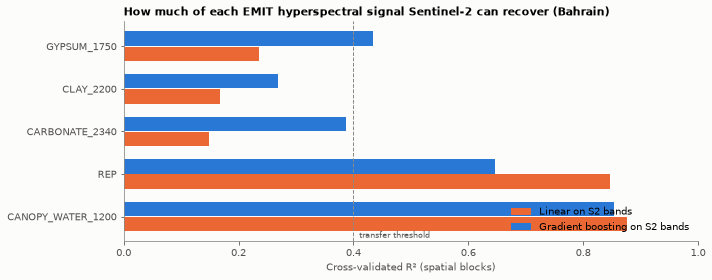

,target,pixels,n,r2_linear,r2_boosted,mae_boosted,hyperspectral_only_info_pct
0,GYPSUM_1750,soil,35175,0.236,0.433,0.007,56.651
1,CLAY_2200,soil,35175,0.168,0.268,0.008,73.159
2,CARBONATE_2340,soil,35175,0.149,0.386,0.010,61.378
3,REP,veg,1128,0.846,0.647,0.572,35.288
4,CANOPY_WATER_1200,veg,1128,0.877,0.853,0.008,14.697


In [5]:
cv = hyperspectral.evaluate_transfer(edf)
cv.to_csv(config.RESULTS_DIR / "hyperspectral_transfer_cv.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(cv))
ax.barh(y + 0.18, cv["r2_linear"].clip(lower=0), height=0.34, color=viz.CAT[1], label="Linear on S2 bands")
ax.barh(y - 0.18, cv["r2_boosted"].clip(lower=0), height=0.34, color=viz.CAT[0], label="Gradient boosting on S2 bands")
ax.set_yticks(y, cv["target"]); ax.set_xlim(0, 1); ax.axvline(0.4, color=viz.MUTED, ls="--", lw=1)
ax.text(0.41, len(cv) - 0.5, "transfer threshold", fontsize=8, color=viz.INK2)
ax.set_xlabel("Cross-validated R² (spatial blocks)"); ax.legend(loc="lower right"); ax.invert_yaxis()
ax.set_title("How much of each EMIT hyperspectral signal Sentinel-2 can recover (Bahrain)", loc="left")
fig.tight_layout(); viz.save(fig, "12_hs_transfer_r2.png"); plt.show()
cv.round(3)

Sentinel-2 recovers the 6 hyperspectral soil classes with balanced accuracy 0.58 (chance = 0.17)


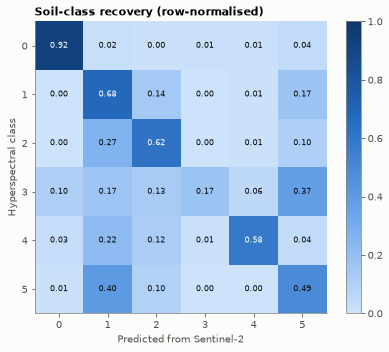

In [6]:
print(f"Sentinel-2 recovers the {rec['k']} hyperspectral soil classes with balanced accuracy "
      f"{rec['balanced_accuracy']:.2f} (chance = {rec['chance']:.2f})")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(rec["confusion"].to_numpy(), cmap=viz.SEQ_BLUE, vmin=0, vmax=1)
ax.set_xlabel("Predicted from Sentinel-2"); ax.set_ylabel("Hyperspectral class")
ax.set_xticks(range(rec["k"])); ax.set_yticks(range(rec["k"]))
for i in range(rec["k"]):
    for j in range(rec["k"]):
        v = rec["confusion"].to_numpy()[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.5 else viz.INK)
plt.colorbar(im, ax=ax, fraction=0.04); ax.set_title("Soil-class recovery (row-normalised)", loc="left")
fig.tight_layout(); viz.save(fig, "13_hs_soil_confusion.png"); plt.show()
json.dump({"soil_class_balanced_accuracy": rec["balanced_accuracy"], "chance": rec["chance"], "k": rec["k"]},
          open(config.RESULTS_DIR / "hyperspectral_soil_recovery.json", "w"), indent=2)

## 4 · What this means for Ecoverse
- The **gypsum (salinity-related) layer used in the main analysis is measured directly by EMIT over Bahrain**, not inferred.
- Targets with **low R²** (the "hyperspectral-only information" column) and soil classes Sentinel-2 confuses are the measurements that
  justify **Satellite 813**: they separate, for example, a gypsum-rich sabkha crust (where only halophytes such as *Suaeda*, glasswort or
  *Salvadora* survive) from a bright but non-saline sand (where *Haloxylon* or *Pennisetum* are cheaper).
- Caveats: one EMIT date (17 June 2023), 60 m pixels, Sentinel-2 simulated from EMIT spectra rather than co-incident real Sentinel-2,
  and no field spectra yet.